In [4]:
import sys
from pathlib import Path

# Make src/ importable from the notebook
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATA = PROJECT_ROOT / "data" / "processed"
print("Project root:", PROJECT_ROOT)
print("Figures dir:", FIG_DIR)
print("Data dir exists:", DATA.exists())

Project root: c:\Users\Gadda\OneDrive\Desktop\log-anamoly-detector
Figures dir: c:\Users\Gadda\OneDrive\Desktop\log-anamoly-detector\reports\figures
Data dir exists: True


In [5]:
scores = pd.read_parquet(DATA / "anomaly_scores.parquet")
per_min = pd.read_parquet(DATA / "minute_anomalies.parquet")
templates = pd.read_parquet(DATA / "templates.parquet")

print(f"scores:    {scores.shape}")
print(f"per_min:   {per_min.shape}")
print(f"templates: {templates.shape}")
print(f"anomalies: {scores['pred_is_anomaly'].sum():,}")

scores:    (56482, 10)
per_min:   (8258, 7)
templates: (56482, 7)
anomalies: 564


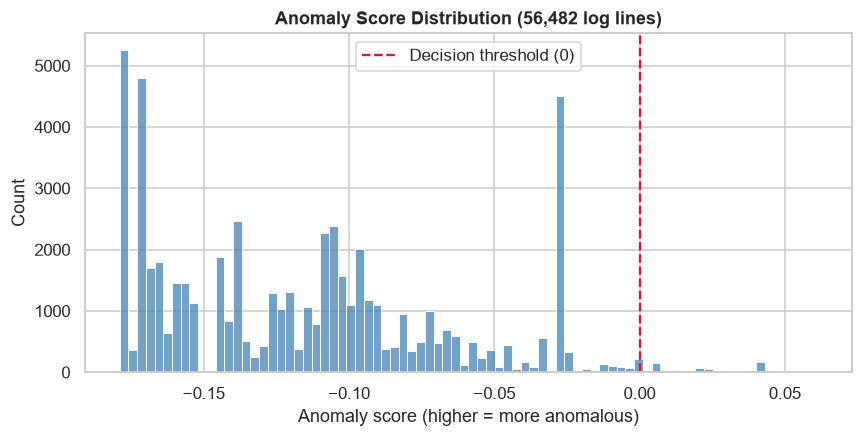

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(scores["anomaly_score"], bins=80, ax=ax, color="steelblue")
ax.axvline(0, color="crimson", linestyle="--", linewidth=1.5, label="Decision threshold (0)")
ax.set_title("Anomaly Score Distribution (56,482 log lines)", fontsize=12, weight="bold")
ax.set_xlabel("Anomaly score (higher = more anomalous)")
ax.set_ylabel("Count")
ax.legend()
fig.savefig(FIG_DIR / "01_score_distribution.png")
plt.show()

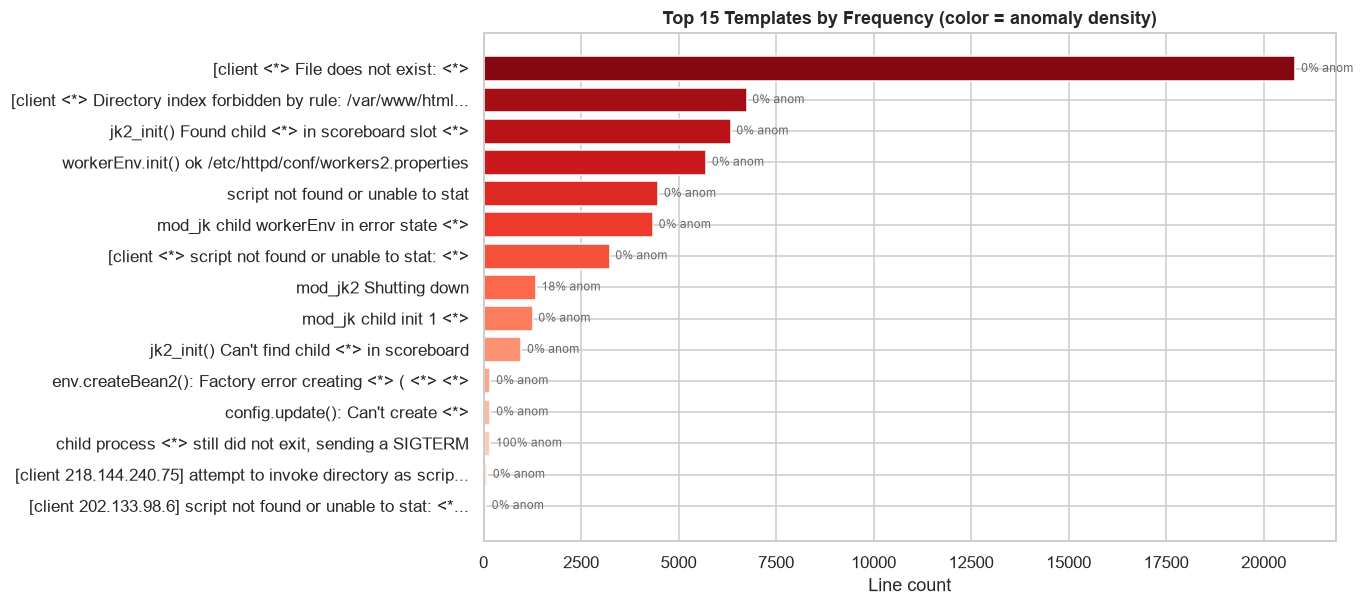

In [7]:
top = (
    scores.groupby("template")
    .agg(total=("raw", "size"), anomalies=("pred_is_anomaly", "sum"))
    .assign(rate=lambda d: d["anomalies"] / d["total"])
    .sort_values("total", ascending=False)
    .head(15)
    .sort_values("total")
)

fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("Reds", n_colors=len(top))
bars = ax.barh([t[:60] + ("..." if len(t) > 60 else "") for t in top.index],
               top["total"], color=colors)
for bar, (_, row) in zip(bars, top.iterrows()):
    ax.text(bar.get_width() + 150, bar.get_y() + bar.get_height()/2,
            f"{row['rate']:.0%} anom", va="center", fontsize=8, color="dimgray")
ax.set_title("Top 15 Templates by Frequency (color = anomaly density)", fontsize=12, weight="bold")
ax.set_xlabel("Line count")
fig.savefig(FIG_DIR / "02_top_templates.png")
plt.show()

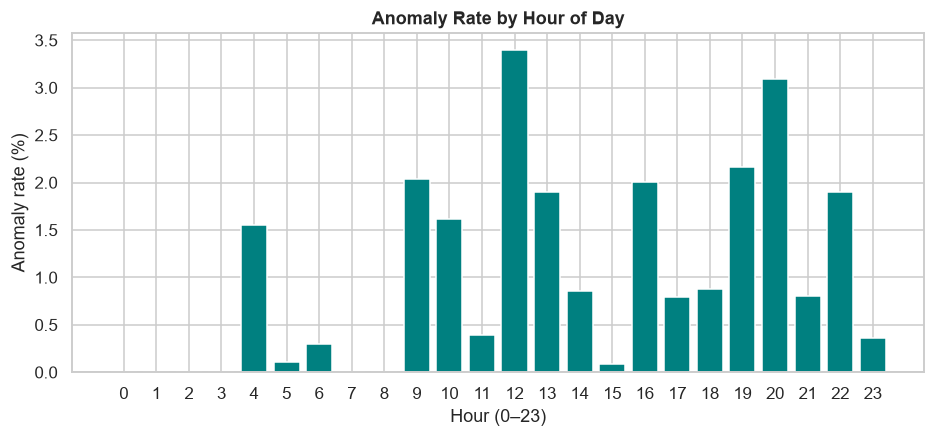

In [8]:
scores["hour"] = pd.to_datetime(scores["ts"], errors="coerce").dt.hour
by_hour = scores.groupby("hour")["pred_is_anomaly"].agg(["sum", "count"])
by_hour["rate"] = by_hour["sum"] / by_hour["count"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour.index, by_hour["rate"] * 100, color="teal")
ax.set_title("Anomaly Rate by Hour of Day", fontsize=12, weight="bold")
ax.set_xlabel("Hour (0–23)")
ax.set_ylabel("Anomaly rate (%)")
ax.set_xticks(range(24))
fig.savefig(FIG_DIR / "03_anomaly_by_hour.png")
plt.show()

C:\Users\Gadda\AppData\Local\Temp\ipykernel_23228\4102324882.py:12: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.savefig(FIG_DIR / "04_anomaly_timeline.png")
c:\Users\Gadda\OneDrive\Desktop\log-anamoly-detector\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


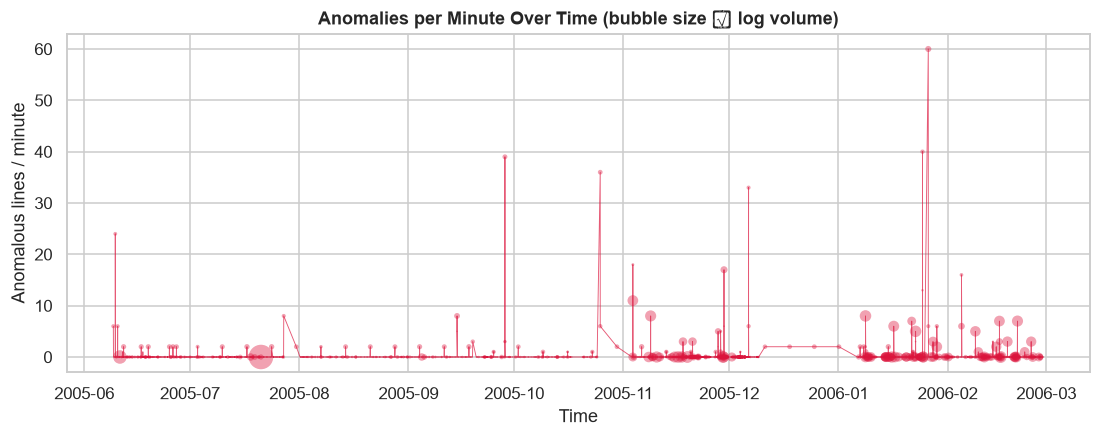

In [9]:
per_min_sorted = per_min.sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(per_min_sorted.index, per_min_sorted["n_anomalies"],
        color="crimson", linewidth=0.6, alpha=0.7)
ax.scatter(per_min_sorted.index,
           per_min_sorted["n_anomalies"],
           s=per_min_sorted["n_lines"] / 5,
           c="crimson", alpha=0.4, edgecolor="none")
ax.set_title("Anomalies per Minute Over Time (bubble size ∝ log volume)", fontsize=12, weight="bold")
ax.set_xlabel("Time")
ax.set_ylabel("Anomalous lines / minute")
fig.savefig(FIG_DIR / "04_anomaly_timeline.png")
plt.show()

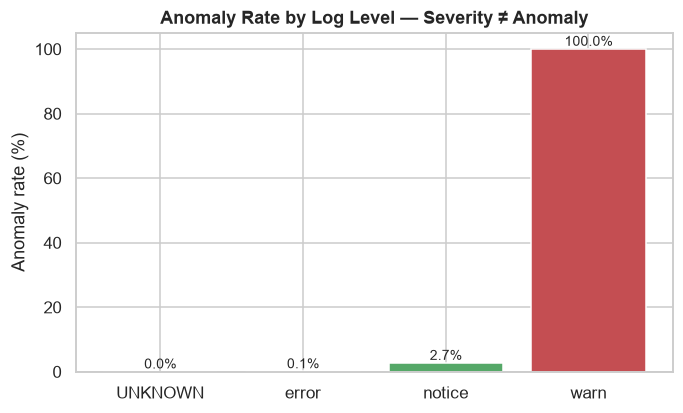

In [10]:
lvl = scores.groupby("level")["pred_is_anomaly"].agg(["sum", "count"])
lvl["rate"] = lvl["sum"] / lvl["count"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(lvl.index, lvl["rate"] * 100,
              color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for bar, rate in zip(bars, lvl["rate"] * 100):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{rate:.1f}%", ha="center", fontsize=9)
ax.set_title("Anomaly Rate by Log Level — Severity ≠ Anomaly", fontsize=12, weight="bold")
ax.set_ylabel("Anomaly rate (%)")
fig.savefig(FIG_DIR / "05_level_vs_anomaly.png")
plt.show()

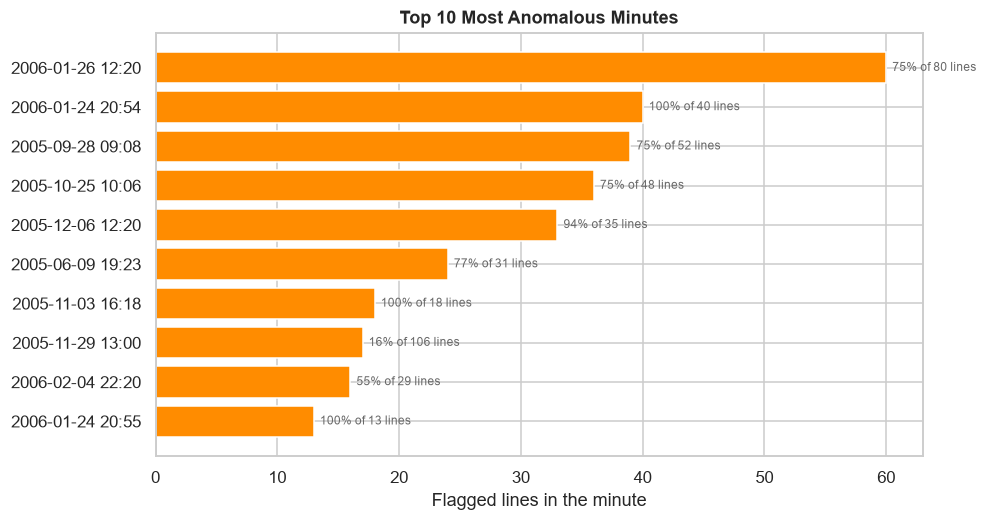

In [11]:
top_minutes = (
    per_min.query("n_lines >= 5")
    .sort_values("n_anomalies", ascending=False)
    .head(10)
    .sort_values("n_anomalies")
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([str(ts)[:16] for ts in top_minutes.index],
        top_minutes["n_anomalies"], color="darkorange")
for i, (_, row) in enumerate(top_minutes.iterrows()):
    ax.text(row["n_anomalies"] + 0.5, i,
            f"{row['anomaly_rate']:.0%} of {int(row['n_lines'])} lines",
            va="center", fontsize=8, color="dimgray")
ax.set_title("Top 10 Most Anomalous Minutes", fontsize=12, weight="bold")
ax.set_xlabel("Flagged lines in the minute")
fig.savefig(FIG_DIR / "06_top_minutes.png")
plt.show()

In [12]:
import os
for f in sorted(os.listdir(FIG_DIR)):
    print(f, os.path.getsize(FIG_DIR / f) // 1024, "KB")

01_score_distribution.png 23 KB
02_top_templates.png 82 KB
03_anomaly_by_hour.png 23 KB
04_anomaly_timeline.png 51 KB
05_level_vs_anomaly.png 20 KB
06_top_minutes.png 43 KB
